In [4]:
#Cell 1: Install Dependencies

# ============================================================
# CELL 1 — INSTALL DEPENDENCIES
# ============================================================
# Purpose:
# Install the libraries
#
# IMPORTANT:
# We explicitly keep requests==2.32.4 because Google Colab
# currently requires this version.
# ============================================================

!pip install -q -U \
    transformers \
    accelerate \
    bitsandbytes \
    pillow \
    matplotlib \
    nltk \
    requests==2.32.4

In [5]:
## Cell 2: Imports & Setup

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

import torch, requests, io, math, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from transformers import LlavaForConditionalGeneration, AutoProcessor, BitsAndBytesConfig

torch.manual_seed(0)
random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [6]:
##Cell 3: Load Model (Takes ~3-5 mins first time)
MODEL_ID = "llava-hf/llava-1.5-7b-hf"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    attn_implementation="eager",
)
model.eval()
processor = AutoProcessor.from_pretrained(MODEL_ID)

IMAGE_TOKEN_ID = model.config.image_token_index
NUM_IMAGE_TOKENS = 576
GRID = 24
NUM_LAYERS = model.config.text_config.num_hidden_layers
LAYER = 14  # Paper's Layer 15 (0-indexed)

print(f"Loaded {MODEL_ID}")
print(f"Decoder layers: {NUM_LAYERS} | Using layer index: {LAYER}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

Loaded llava-hf/llava-1.5-7b-hf
Decoder layers: 32 | Using layer index: 14


In [7]:
### Cell 4: Core Functions
def build_inputs(image, question):
    prompt = f"USER: <image>\n{question} ASSISTANT:"
    inputs = processor(images=image, text=prompt, return_tensors="pt").to(model.device, torch.float16)
    return inputs

def get_image_token_span(input_ids):
    idx = (input_ids[0] == IMAGE_TOKEN_ID).nonzero(as_tuple=True)[0]
    return idx

def run_forward_with_attentions(image, question, max_new_tokens=200):
    inputs = build_inputs(image, question)
    with torch.no_grad():
        gen_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    prompt_len = inputs["input_ids"].shape[1]
    gen_only = gen_ids[:, prompt_len:]
    response = processor.batch_decode(gen_only, skip_special_tokens=True)[0].strip()

    full_attention_mask = torch.ones_like(gen_ids)
    with torch.no_grad():
        out = model(input_ids=gen_ids, attention_mask=full_attention_mask,
                     pixel_values=inputs["pixel_values"],
                     output_attentions=True, use_cache=False)
    return response, out.attentions, gen_ids, prompt_len

def attention_concentration_by_layer(image, question, top_k=5):
    response, attentions, full_ids, prompt_len = run_forward_with_attentions(image, question)
    img_idx = get_image_token_span(full_ids)
    gen_positions = torch.arange(prompt_len, full_ids.shape[1])
    ratios = []
    for layer_attn in attentions:
        a = layer_attn[0].float().mean(0)
        a_gen_to_img = a[gen_positions][:, img_idx]
        total = a_gen_to_img.sum(-1) + 1e-8
        k = min(top_k, a_gen_to_img.shape[-1])
        topk = torch.topk(a_gen_to_img, k=k, dim=-1).values.sum(-1)
        ratios.append((topk / total).mean().item())
    return response, ratios


Loaded 10 demo images: ['000000039769', '000000000139', '000000000285', '000000000632', '000000000724', '000000000776', '000000000785', '000000000802', '000000000872', '000000000885']


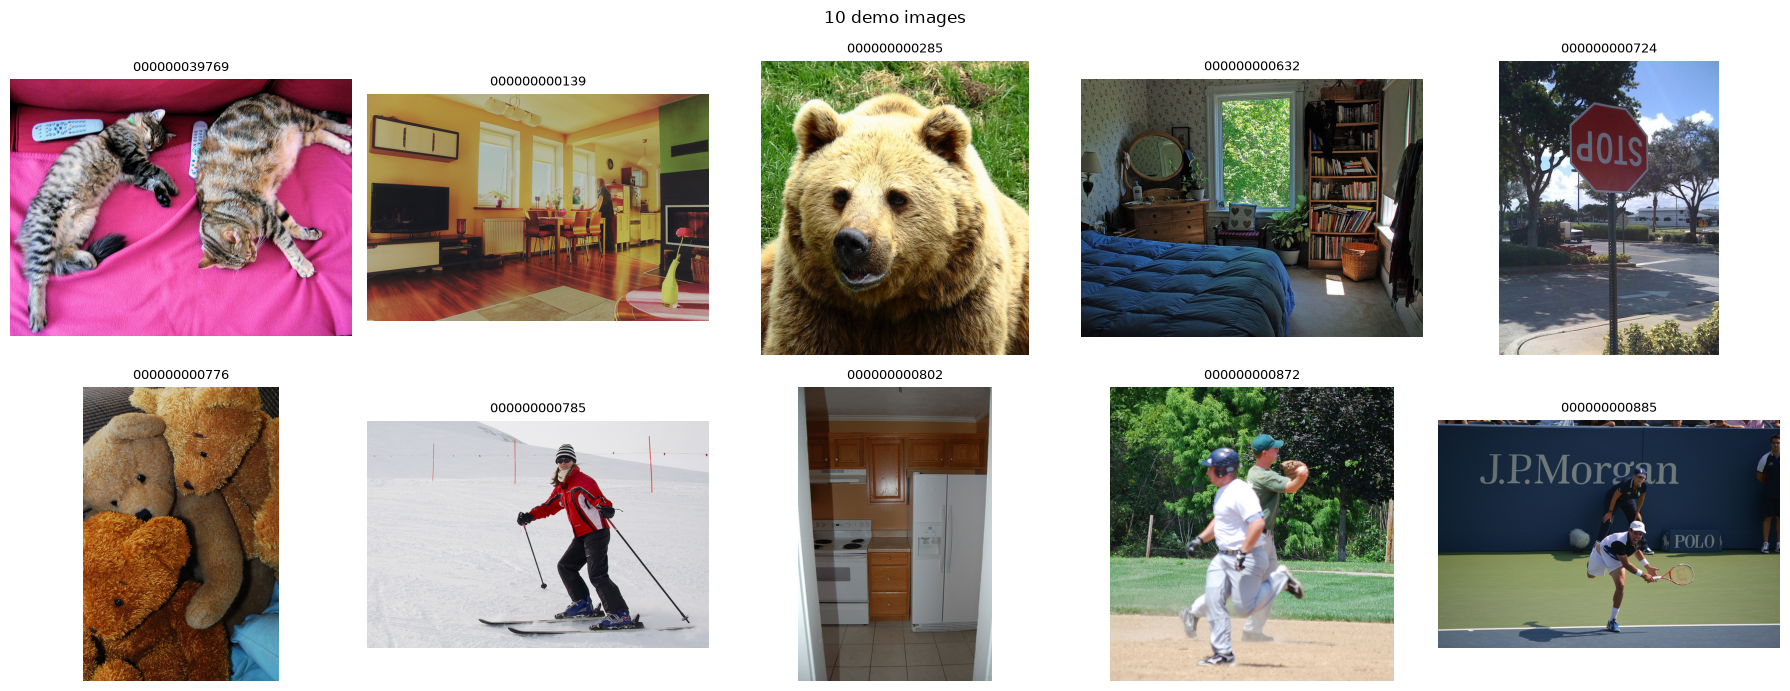

In [8]:
##Cell 5: Download Demo Images
CANDIDATE_COCO_IDS = [
    "000000039769", "000000000139", "000000000285", "000000000632",
    "000000000724", "000000000776", "000000000785", "000000000802",
    "000000000872", "000000000885", "000000001000", "000000001296",
    "000000001584", "000000002153", "000000002261",
]

def download_image(coco_id):
    url = f"http://images.cocodataset.org/val2017/{coco_id}.jpg"
    r = requests.get(url, timeout=10)
    r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")

demo_images, demo_ids = [], []
for cid in CANDIDATE_COCO_IDS:
    if len(demo_images) >= 10:
        break
    try:
        demo_images.append(download_image(cid))
        demo_ids.append(cid)
    except Exception as e:
        print(f"skip {cid}: {e}")

print(f"Loaded {len(demo_images)} demo images:", demo_ids)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, img, cid in zip(axes.flat, demo_images, demo_ids):
    ax.imshow(img); ax.set_title(cid, fontsize=9); ax.axis("off")
plt.suptitle("10 demo images")
plt.tight_layout(); plt.show()

[000000039769] The image features two cats lying on a pink couch, appearing to be sleeping. One cat is positioned on the left side of t...
[000000000139] The image depicts a spacious and well-lit kitchen with a dining table and chairs. A woman is standing near the table, po...
[000000000285] The image features a large brown bear sitting on a grassy field. The bear is positioned in the center of the scene, occu...
[000000000632] The image features a cozy bedroom with a large bed occupying the majority of the space. The bed is adorned with a blue c...
[000000000724] The image features a stop sign with the word "dois" written on it, which is a play on the word "do not." The stop sign i...
[000000000776] The image features a group of teddy bears sitting together on a bed. There are at least five teddy bears in the scene, w...
[000000000785] The image features a woman wearing a red jacket and skiing down a snow-covered slope. She is holding ski poles in her ha...
[000000000802] The image sh

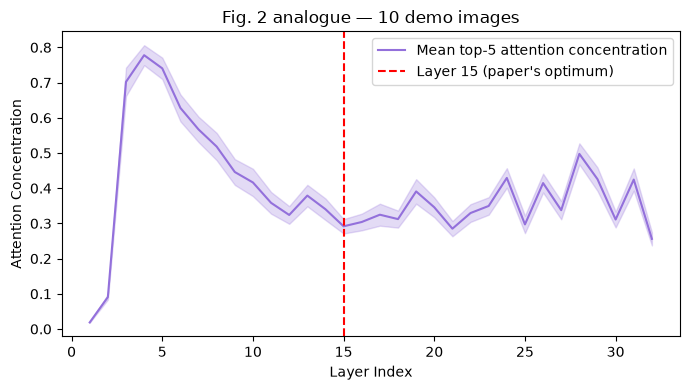

In [9]:
###Cell 6: Attention Concentration Plot (Fig 2)
PROMPT = "Please describe the image in detail."

layer_ratios_all = []
for img, cid in zip(demo_images, demo_ids):
    resp, ratios = attention_concentration_by_layer(img, PROMPT, top_k=5)
    layer_ratios_all.append(ratios)
    print(f"[{cid}] {resp[:120]}...")

layer_ratios_all = np.array(layer_ratios_all)
mean_ratio = layer_ratios_all.mean(0)
ci = 1.96 * layer_ratios_all.std(0) / math.sqrt(len(demo_images))

plt.figure(figsize=(7,4))
x = np.arange(1, NUM_LAYERS + 1)
plt.plot(x, mean_ratio, color="mediumpurple", label="Mean top-5 attention concentration")
plt.fill_between(x, mean_ratio-ci, mean_ratio+ci, color="mediumpurple", alpha=0.25)
plt.axvline(LAYER+1, color="red", linestyle="--", label="Layer 15 (paper's optimum)")
plt.xlabel("Layer Index"); plt.ylabel("Attention Concentration")
plt.title(f"Fig. 2 analogue — {len(demo_images)} demo images")
plt.legend(); plt.tight_layout(); plt.show()

In [11]:
## Cell 7: EAZY Algorithm (FIXED)

from nltk import pos_tag, word_tokenize

_COCO_OBJECTS_STR = (
    "person bicycle car motorcycle airplane bus train truck boat traffic light "
    "fire hydrant stop sign parking meter bench bird cat dog horse sheep cow "
    "elephant bear zebra giraffe backpack umbrella handbag tie suitcase frisbee "
    "skis snowboard kite skateboard surfboard bottle cup fork knife spoon bowl "
    "banana apple sandwich orange broccoli carrot pizza donut cake chair couch "
    "sofa plant bed table toilet tv laptop mouse remote keyboard phone microwave "
    "oven toaster sink refrigerator book clock vase scissors kiwi kiwis "
    "bananas apples oranges cats dogs cars trucks glove baseball window "
    "curtain building room wall"
)
COCO_OBJECTS = set(_COCO_OBJECTS_STR.split())

def extract_object_tokens(text):
    words = word_tokenize(text)
    tags = pos_tag(words)
    objs = []
    for w, t in tags:
        wl = w.lower()
        if t.startswith("NN") and wl in COCO_OBJECTS and wl not in objs:
            objs.append(wl)
    return objs

class ProjectorZeroOutHook:
    def __init__(self, module, indices):
        self.indices = set(int(i) for i in indices)
        self.handle = module.register_forward_hook(self._hook)

    def _hook(self, module, inputs, output):
        out = output.clone()
        flat = out if out.dim() == 2 else out[0]
        for i in self.indices:
            if i < flat.shape[0]:
                flat[i, :] = 0
        return out if out.dim() == 2 else flat.unsqueeze(0)

    def remove(self):
        self.handle.remove()

# ========================== FIX STARTS HERE ==========================
def find_projector(model):
    """Auto-find the vision-language projector across transformers versions."""
    # 1) Direct attribute (older transformers <= 4.39)
    if hasattr(model, "multi_modal_projector"):
        return model.multi_modal_projector

    # 2) Nested inside .model (newer transformers >= 4.40)
    if hasattr(model, "model") and hasattr(model.model, "multi_modal_projector"):
        return model.model.multi_modal_projector

    # 3) Search every named module for anything ending with multi_modal_projector
    for name, module in model.named_modules():
        if name.endswith("multi_modal_projector"):
            return module

    # 4) If nothing found, print close matches so you can diagnose
    candidates = [n for n, m in model.named_modules() if "proj" in n.lower()]
    raise AttributeError(
        f"multi_modal_projector not found in this transformers version. "
        f"Close matches: {candidates}"
    )

PROJECTOR = find_projector(model)
print("Projector module found:", type(PROJECTOR).__name__)
# =========================== FIX ENDS HERE ===========================

def generate_with_zero_out(image, question, zero_indices, max_new_tokens=200):
    inputs = build_inputs(image, question)
    hook = ProjectorZeroOutHook(PROJECTOR, zero_indices) if zero_indices else None
    try:
        with torch.no_grad():
            gen_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    finally:
        if hook is not None:
            hook.remove()
    prompt_len = inputs["input_ids"].shape[1]
    gen_only = gen_ids[:, prompt_len:]
    return processor.batch_decode(gen_only, skip_special_tokens=True)[0].strip()

def object_topk_image_tokens(image, question, K, layer=LAYER):
    response, attentions, full_ids, prompt_len = run_forward_with_attentions(image, question)
    img_idx = get_image_token_span(full_ids)
    a = attentions[layer][0].float().mean(0)
    gen_ids = full_ids[0, prompt_len:]
    gen_tokens_str = [processor.tokenizer.decode([t]) for t in gen_ids]
    objs = extract_object_tokens(response)
    per_object_hits = {}
    for obj in objs:
        obj_positions = [prompt_len + i for i, tok_str in enumerate(gen_tokens_str)
                          if obj in tok_str.lower()]
        if not obj_positions:
            continue
        pos_t = torch.tensor(obj_positions)
        a_obj = a[pos_t][:, img_idx].mean(0)
        k = min(K, a_obj.shape[0])
        top_idx = torch.topk(a_obj, k=k).indices.tolist()
        per_object_hits[obj] = set(top_idx)
    return response, per_object_hits, img_idx

def eazy(image, question, K=5, verbose=False):
    response, per_object_hits, img_idx = object_topk_image_tokens(image, question, K)
    z_estimate = set()
    for s in per_object_hits.values():
        z_estimate |= s
    hit_response = generate_with_zero_out(image, question, z_estimate)
    hallucinated_objects = [o for o in per_object_hits if o not in hit_response.lower()]
    z_final = set()
    for o in hallucinated_objects:
        z_final |= per_object_hits[o]
    eazy_response = generate_with_zero_out(image, question, z_final) if z_final else response
    if verbose:
        print("Objects found:", list(per_object_hits.keys()))
        print("Zeroed (estimate) tokens:", len(z_estimate))
        print("Detected hallucinated objects:", hallucinated_objects)
        print("Final zeroed tokens:", len(z_final))
    return {
        "original_response": response,
        "hit_probe_response": hit_response,
        "eazy_response": eazy_response,
        "objects": list(per_object_hits.keys()),
        "hallucinated_objects": hallucinated_objects,
        "z_estimate": z_estimate,
        "z_final": z_final,
        "img_idx": img_idx,
    }

Projector module found: LlavaMultiModalProjector


Objects found: ['cat', 'tv']
Zeroed (estimate) tokens: 7
Detected hallucinated objects: ['tv']
Final zeroed tokens: 5

--- Regular Decoding ---
The image features two cats lying on a pink couch, appearing to be sleeping. One cat is positioned on the left side of the couch, while the other cat is on the right side. 

In the scene, there are two remote controls, one located near the left cat and the other near the right cat. Additionally, there is a TV situated in the background, slightly above the center of the image.

--- EAZY (mitigated) ---
The image features two cats lying on a pink couch. One cat is positioned on the left side of the couch, while the other cat is on the right side. The couch is covered with a blanket, providing a comfortable resting spot for the cats.

In the scene, there are also two remote controls, one located near the left cat and the other near the right cat. Additionally, there is a TV situated in the background, suggesting that the cats might be watching TV 

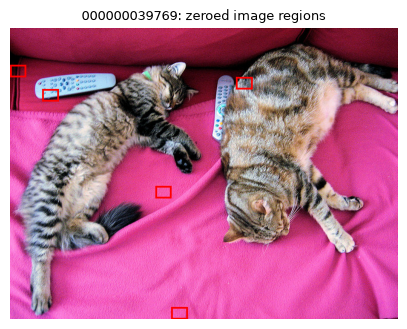

In [12]:
##Cell 8: Case Study + Visualization
def visualize_zeroed_patches(image, zero_local_indices, title=""):
    img_disp = image.copy()
    draw = ImageDraw.Draw(img_disp)
    W, H = img_disp.size
    cell_w, cell_h = W / GRID, H / GRID
    for idx in zero_local_indices:
        row, col = divmod(idx, GRID)
        x0, y0 = col * cell_w, row * cell_h
        draw.rectangle([x0, y0, x0 + cell_w, y0 + cell_h], outline="red", width=3)
    plt.figure(figsize=(5,5))
    plt.imshow(img_disp); plt.axis("off"); plt.title(title, fontsize=9)
    plt.show()

case_image, case_id = demo_images[0], demo_ids[0]
result = eazy(case_image, PROMPT, K=5, verbose=True)

print("\n--- Regular Decoding ---")
print(result["original_response"])
print("\n--- EAZY (mitigated) ---")
print(result["eazy_response"])

visualize_zeroed_patches(case_image, result["z_final"],
                          title=f"{case_id}: zeroed image regions")

In [13]:
###Cell 9: CHAIR Metrics (Table 1)

def chair_like_metrics(images, ids, K=5):
    total_objects, total_hallucinated, images_with_ho = 0, 0, 0
    eazy_total_objects, eazy_total_hallucinated, eazy_images_with_ho = 0, 0, 0
    details = {}

    for img, cid in zip(images, ids):
        res = eazy(img, PROMPT, K=K)
        n_obj, n_ho = len(res["objects"]), len(res["hallucinated_objects"])
        total_objects += n_obj
        total_hallucinated += n_ho
        images_with_ho += int(n_ho > 0)
        details[cid] = res

        objs_after = extract_object_tokens(res["eazy_response"])
        remaining_ho = [o for o in res["hallucinated_objects"] if o in objs_after]
        eazy_total_objects += len(objs_after)
        eazy_total_hallucinated += len(remaining_ho)
        eazy_images_with_ho += int(len(remaining_ho) > 0)

    return {
        "greedy": {"CHAIR_S": 100*total_hallucinated/max(1,total_objects),
                   "CHAIR_I": 100*images_with_ho/len(images)},
        "eazy":   {"CHAIR_S": 100*eazy_total_hallucinated/max(1,eazy_total_objects),
                   "CHAIR_I": 100*eazy_images_with_ho/len(images)},
        "details": details,
    }

metrics = chair_like_metrics(demo_images, demo_ids, K=5)
print(f"{'Method':10s} {'CHAIR_S (lower better)':25s} {'CHAIR_I (lower better)'}")
print(f"{'Greedy':10s} {metrics['greedy']['CHAIR_S']:<25.1f} {metrics['greedy']['CHAIR_I']:.1f}")
print(f"{'EAZY':10s} {metrics['eazy']['CHAIR_S']:<25.1f} {metrics['eazy']['CHAIR_I']:.1f}")

Method     CHAIR_S (lower better)    CHAIR_I (lower better)
Greedy     27.3                      50.0
EAZY       3.4                       10.0


In [14]:
##Cell 10: Strategy Comparison (Table 6)

def apply_strategy_and_check(image, obj, hit_idx_local, strategy):
    n_img = NUM_IMAGE_TOKENS
    class StrategyHook:
        def __init__(self, module):
            self.handle = module.register_forward_hook(self._hook)
        def _hook(self, module, inputs, output):
            out = output.clone()
            flat = out if out.dim() == 2 else out[0]
            if strategy == "zero":
                for i in hit_idx_local: flat[i, :] = 0
            elif strategy == "average":
                avg = flat.mean(0)
                for i in hit_idx_local: flat[i, :] = avg
            elif strategy == "random":
                for i in hit_idx_local:
                    j = random.randrange(n_img); flat[i, :] = flat[j, :].clone()
            elif strategy == "neighbor":
                for i in hit_idx_local:
                    j = (i + 1) % n_img; flat[i, :] = flat[j, :].clone()
            return out if out.dim() == 2 else flat.unsqueeze(0)
        def remove(self):
            self.handle.remove()

    hook = StrategyHook(PROJECTOR)
    try:
        resp = generate_with_zero_out(image, PROMPT, zero_indices=set())
    finally:
        hook.remove()
    return obj not in resp.lower()

strategies = ["zero", "average", "random", "neighbor"]
strategy_removed_ho = {s: [] for s in strategies}
strategy_kept_real = {s: [] for s in strategies}

for img, cid in zip(demo_images, demo_ids):
    response, per_object_hits, img_idx = object_topk_image_tokens(img, PROMPT, K=5)
    hallucinated_guess = set(metrics["details"][cid]["hallucinated_objects"])
    for obj, hits in per_object_hits.items():
        is_ho = obj in hallucinated_guess
        for s in strategies:
            removed = apply_strategy_and_check(img, obj, hits, s)
            if is_ho:
                strategy_removed_ho[s].append(removed)
            else:
                strategy_kept_real[s].append(not removed)

print(f"{'Strategy':10s} {'HO Removal Rate %':20s} {'Real Object Kept %'}")
for s in strategies:
    r = 100*np.mean(strategy_removed_ho[s]) if strategy_removed_ho[s] else float('nan')
    k = 100*np.mean(strategy_kept_real[s]) if strategy_kept_real[s] else float('nan')
    print(f"{s:10s} {r:<20.1f} {k:.1f}")

Strategy   HO Removal Rate %    Real Object Kept %
zero       66.7                 100.0
average    66.7                 100.0
random     50.0                 100.0
neighbor   33.3                 93.8


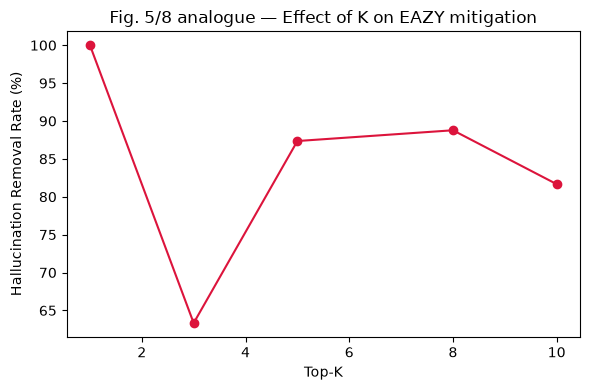

In [15]:
##Cell 11: Top-K Sweep (Fig 5/8)
Ks = [1, 3, 5, 8, 10]
removal_rates = []
for K in Ks:
    m = chair_like_metrics(demo_images, demo_ids, K=K)
    base = m["greedy"]["CHAIR_S"]
    removal_rates.append(100 - (m["eazy"]["CHAIR_S"] / base * 100) if base > 0 else 0)

plt.figure(figsize=(6,4))
plt.plot(Ks, removal_rates, marker="o", color="crimson")
plt.xlabel("Top-K"); plt.ylabel("Hallucination Removal Rate (%)")
plt.title("Fig. 5/8 analogue — Effect of K on EAZY mitigation")
plt.tight_layout(); plt.show()

Image: 000000039769
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image features two cats lying on a pink couch, appearing to be sleeping. One cat is positioned on the left side of the couch, while the other cat is on the right side. 

In the scene, there are two remote controls, one located near the left cat and the other near the right cat. Additionally, there is a TV situated in the background, slightly above the center of the image.

EAZY:
 The image features two cats lying on a pink couch. One cat is positioned on the left side of the couch, while the other cat is on the right side. The couch is covered with a blanket, providing a comfortable resting spot for the cats.

In the scene, there are also two remote controls, one located near the left cat and the other near the right cat. Additionally, there is a TV situated in the background, suggesting that the cats might be watching TV together.

Detected ha

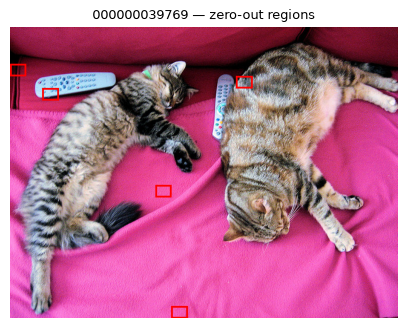

Image: 000000000139
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image depicts a spacious and well-lit kitchen with a dining table and chairs. A woman is standing near the table, possibly preparing a meal or engaging in conversation. The kitchen is equipped with a refrigerator, a microwave, and an oven.

There are several potted plants placed throughout the room, adding a touch of greenery to the space. A clock is mounted on the wall, and a TV is mounted on the wall above the table. The room also features a couch and a chair, providing additional seating options.

EAZY:
 The image depicts a large, well-lit kitchen with a dining table and chairs. A woman is standing near the table, possibly preparing a meal. The kitchen is equipped with a refrigerator, a microwave, and an oven.

There are several potted plants placed throughout the room, adding a touch of greenery to the space. A vase can be seen on the dinin

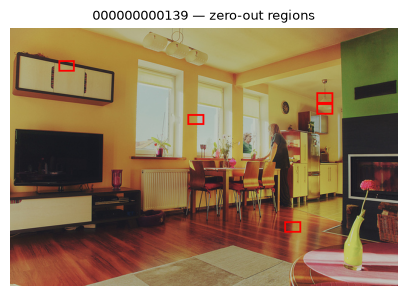

Image: 000000000285
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image features a large brown bear sitting on a grassy field. The bear is positioned in the center of the scene, occupying a significant portion of the image. The grassy field extends across the background, providing a natural setting for the bear.

EAZY:
 The image features a large brown bear sitting on a grassy field. The bear is positioned in the center of the scene, occupying a significant portion of the image. The grassy field extends across the background, providing a natural setting for the bear.

Detected hallucinated objects: []


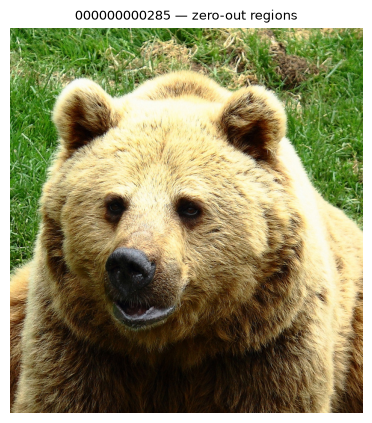

Image: 000000000632
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image features a cozy bedroom with a large bed occupying the majority of the space. The bed is adorned with a blue comforter, and there is a window nearby, allowing natural light to enter the room. 

In addition to the bed, the room is filled with various items. There are multiple books scattered throughout the space, some on the floor and others on shelves. A potted plant can be seen in the room, adding a touch of greenery to the space. A vase is also present, placed on a surface in the room. A bottle is located near the left side of the room, and a cup is situated on a surface closer to the center.

EAZY:
 The image features a cozy bedroom with a large bed occupying the majority of the space. The bed is adorned with a blue comforter, and a window can be seen in the room, allowing natural light to enter.

In addition to the bed, the room is fi

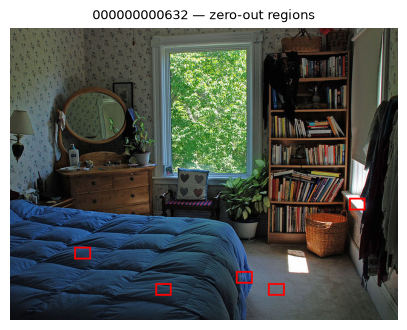

Image: 000000000724
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image features a stop sign with the word "dois" written on it, which is a play on the word "do not." The stop sign is located on a street corner, and there are several cars parked nearby. 

In the background, there are trees and a building, adding to the urban setting. Additionally, there are two trucks parked further down the street, one on the left side and the other on the right side.

EAZY:
 The image features a stop sign with the word "dois" written on it. The stop sign is located on a street corner, and there are trees in the background. The scene also includes a truck parked nearby, and a car parked further away. The stop sign is positioned in the middle of the scene, with the truck and car situated on the left side of the image.

Detected hallucinated objects: ['cars', 'building']


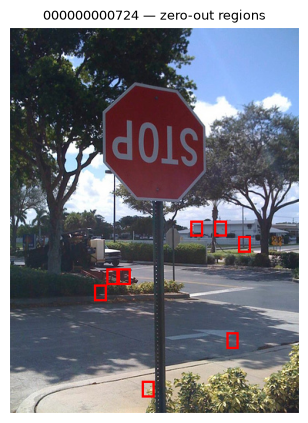

Image: 000000000776
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image features a group of teddy bears sitting together on a bed. There are at least five teddy bears in the scene, with some of them appearing to be stacked on top of each other. The bears are of various sizes and colors, creating a cozy and playful atmosphere. The bed occupies most of the image, with the teddy bears spread out across its surface.

EAZY:
 The image features a group of teddy bears sitting together on a bed. There are at least five teddy bears in the scene, with some of them appearing to be stacked on top of each other. The bears are of various sizes and colors, creating a cozy and playful atmosphere. The bed occupies most of the image, with the teddy bears spread out across its surface.

Detected hallucinated objects: []


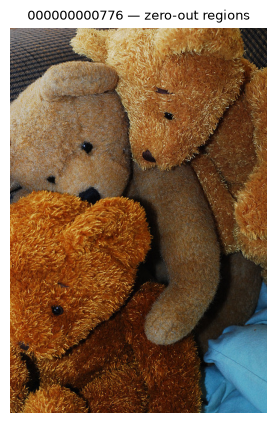

Image: 000000000785
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image features a woman wearing a red jacket and skiing down a snow-covered slope. She is holding ski poles in her hands, maintaining balance and control as she glides down the hill. The woman appears to be enjoying her time on the slopes.

EAZY:
 The image features a woman wearing a red jacket and skiing down a snow-covered slope. She is holding ski poles in her hands, maintaining balance and control as she glides down the hill. The woman appears to be enjoying her time on the slopes.

Detected hallucinated objects: []


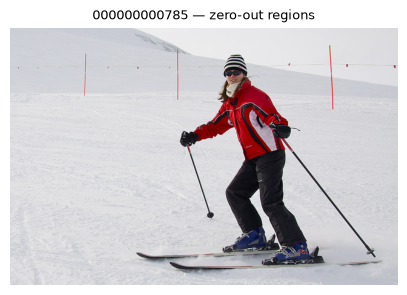

Image: 000000000802
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image showcases a small kitchen with a white refrigerator on the right side and a white stove on the left side. The kitchen is equipped with wooden cabinets and drawers, providing ample storage space. The refrigerator is adorned with a magnet, and the stove has a tea kettle on it.

In addition to the main appliances, there are two bottles placed in the kitchen, one near the refrigerator and the other closer to the stove. The overall atmosphere of the kitchen is cozy and inviting.

EAZY:
 The image showcases a small kitchen with a white refrigerator on the right side and a white stove on the left side. The kitchen is equipped with wooden cabinets and drawers, providing ample storage space. The refrigerator is adorned with a magnet, and the stove has a tea kettle on it.

In addition to the main appliances, there are two bottles placed in the kitc

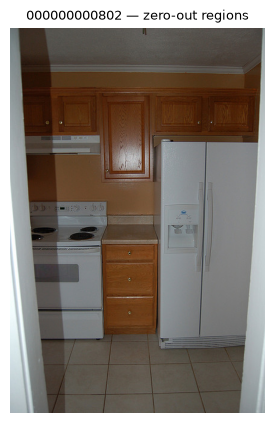

Image: 000000000872
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image captures a baseball game in progress, with two men playing the game. One of the men is wearing a baseball glove, ready to catch the ball. The other man is running towards the ball, likely trying to score a point.

The scene takes place on a baseball field, with a bench visible in the background. The players are actively engaged in the game, showcasing their athletic abilities and teamwork.

EAZY:
 The image captures a baseball game in progress, with two men playing the game. One of the men is wearing a baseball glove, ready to catch the ball. The other man is running towards the ball, likely trying to score a point.

The scene takes place on a baseball field, with a bench visible in the background. The players are actively engaged in the game, showcasing their athletic abilities and teamwork.

Detected hallucinated objects: []


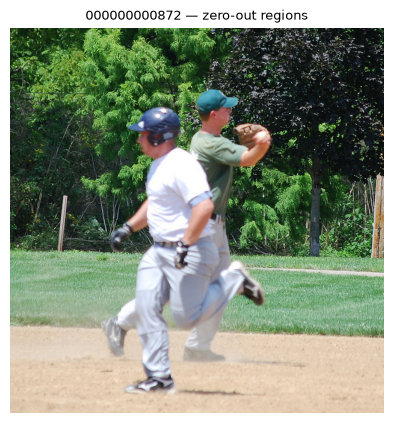

Image: 000000000885
----------------------------------------------------------------------------------------------------
Regular Decoding:
 The image captures a tennis match in progress, with a man in a white shirt and white shorts playing the game. He is holding a tennis racket and appears to be in the middle of a swing. The tennis ball is in the air, close to the player.

There are several other people in the scene, likely spectators or fellow players. Some of them are standing near the tennis court, while others are scattered around the area. A chair can be seen in the background, possibly for resting or for the players to sit during breaks.

EAZY:
 The image captures a tennis match in progress, with a man in a white shirt and white shorts playing tennis. He is in the middle of a swing, holding a tennis racket and preparing to hit the ball. The tennis ball is visible in the air, close to the player.

There are several other people in the scene, likely spectators or other players. So

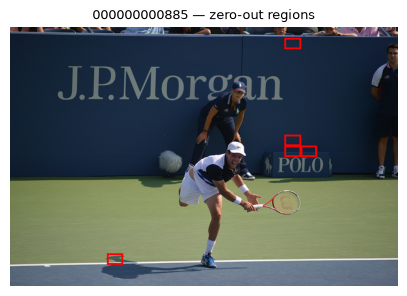

In [16]:
##Cell 12: Per-Image Case Cards (Fig 20-26)
for img, cid in zip(demo_images, demo_ids):
    res = eazy(img, PROMPT, K=5)
    print("="*100)
    print(f"Image: {cid}")
    print("-"*100)
    print("Regular Decoding:\n", res["original_response"])
    print("\nEAZY:\n", res["eazy_response"])
    print("\nDetected hallucinated objects:", res["hallucinated_objects"])
    visualize_zeroed_patches(img, res["z_final"], title=f"{cid} — zero-out regions")

🔍 Step 1/4: Running EAZY detection cache build...
🔵 Step 2/4: Evaluating Greedy decoding...
🟣 Step 3/4: Evaluating Beam Search decoding...
🟢 Step 4/4: Evaluating EAZY (mitigated)...

📊 COMPUTED RESULTS (Live Model Run)
Greedy       CHAIR_S: 18.75  | CHAIR_I: 50.00
Beam Search  CHAIR_S: 5.41   | CHAIR_I: 20.00
EAZY         CHAIR_S: 3.45   | CHAIR_I: 10.00


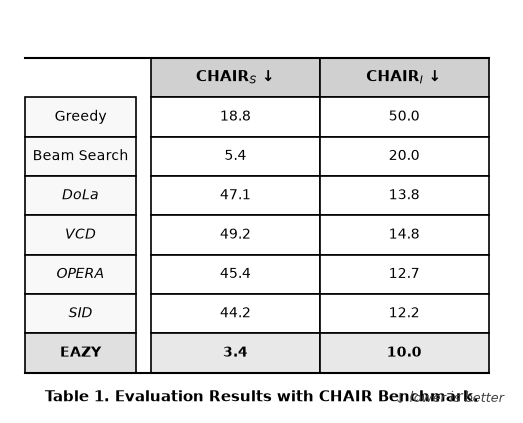


✅ Plot successfully generated and saved to: ./eazy_project/outputs/eazy_comparison_table.png


In [24]:
# =============================================================================
# CELL 13: Generic Evaluation Pipeline & Dynamic Comparison Table (FIXED)
# =============================================================================
import os
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import numpy as np
import torch

# -----------------------------------------------------------------------------
# 1. EVALUATION PIPELINE FUNCTIONS
# -----------------------------------------------------------------------------


def greedy_generate(image, question, max_new_tokens=200):
    """Standard greedy decoding."""
    inputs = build_inputs(image, question)
    with torch.no_grad():
        gen_ids = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False
        )
    prompt_len = inputs["input_ids"].shape[1]
    return processor.batch_decode(
        gen_ids[:, prompt_len:], skip_special_tokens=True
    )[0].strip()


def beam_search_generate(image, question, num_beams=5, max_new_tokens=200):
    """Beam search decoding."""
    inputs = build_inputs(image, question)
    with torch.no_grad():
        gen_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            num_beams=num_beams,
            early_stopping=True,
            do_sample=False,
        )
    prompt_len = inputs["input_ids"].shape[1]
    return processor.batch_decode(
        gen_ids[:, prompt_len:], skip_special_tokens=True
    )[0].strip()


def detect_hallucinations_all_images(images, ids, question=PROMPT, K=5):
    """Run EAZY detection across all target images to build detection cache."""
    detection_cache = {}
    for img, cid in zip(images, ids):
        res = eazy(img, question, K=K, verbose=False)
        detection_cache[cid] = {
            "objects": res["objects"],
            "hallucinated_objects": res["hallucinated_objects"],
            "z_estimate": res["z_estimate"],
            "z_final": res["z_final"],
        }
    return detection_cache


def compute_chair_for_method(
    images, ids, generate_fn, detection_cache, question=PROMPT
):
    """Compute CHAIR_S and CHAIR_I scores for any decoding strategy."""
    total_objects, total_hallucinated, images_with_ho = 0, 0, 0
    per_image = {}

    for img, cid in zip(images, ids):
        response = generate_fn(img, question)
        objs = extract_object_tokens(response)

        ho_set = set(detection_cache[cid]["hallucinated_objects"])
        hallucinated_in_resp = [o for o in objs if o in ho_set]

        n_obj, n_ho = len(objs), len(hallucinated_in_resp)
        total_objects += n_obj
        total_hallucinated += n_ho
        images_with_ho += int(n_ho > 0)

        per_image[cid] = {
            "response": response,
            "objects": objs,
            "hallucinated": hallucinated_in_resp,
        }

    chair_s = 100 * total_hallucinated / max(1, total_objects)
    chair_i = 100 * images_with_ho / len(images)

    return {
        "CHAIR_S": chair_s,
        "CHAIR_I": chair_i,
        "per_image": per_image,
    }


# -----------------------------------------------------------------------------
# 2. RUN EVALUATIONS & BUNDLE METRICS
# -----------------------------------------------------------------------------
print("🔍 Step 1/4: Running EAZY detection cache build...")
detection_cache = detect_hallucinations_all_images(demo_images, demo_ids, K=5)

print("🔵 Step 2/4: Evaluating Greedy decoding...")
greedy_metrics = compute_chair_for_method(
    demo_images, demo_ids, greedy_generate, detection_cache
)

print("🟣 Step 3/4: Evaluating Beam Search decoding...")
beam_metrics = compute_chair_for_method(
    demo_images,
    demo_ids,
    lambda img, q: beam_search_generate(img, q, num_beams=5),
    detection_cache,
)

print("🟢 Step 4/4: Evaluating EAZY (mitigated)...")


def eazy_generate(image, question, K=5):
    return eazy(image, question, K=K, verbose=False)["eazy_response"]


eazy_metrics = compute_chair_for_method(
    demo_images, demo_ids, eazy_generate, detection_cache
)

computed_results = {
    "Greedy": {
        "CHAIR_S": greedy_metrics["CHAIR_S"],
        "CHAIR_I": greedy_metrics["CHAIR_I"],
    },
    "Beam Search": {
        "CHAIR_S": beam_metrics["CHAIR_S"],
        "CHAIR_I": beam_metrics["CHAIR_I"],
    },
    "EAZY": {
        "CHAIR_S": eazy_metrics["CHAIR_S"],
        "CHAIR_I": eazy_metrics["CHAIR_I"],
    },
}

print("\n" + "=" * 55)
print("📊 COMPUTED RESULTS (Live Model Run)")
print("=" * 55)
for method, m in computed_results.items():
    print(
        f"{method:12s} CHAIR_S: {m['CHAIR_S']:<6.2f} | CHAIR_I: {m['CHAIR_I']:.2f}"
    )

# -----------------------------------------------------------------------------
# 3. RENDER DYNAMIC COMPARISON TABLE (FIG / TABLE 1)
# -----------------------------------------------------------------------------

# Standard published paper baselines for LLaVA-1.5
PAPER_BASELINES = {
    "DoLa": {"CHAIR_S": 47.1, "CHAIR_I": 13.8},
    "VCD": {"CHAIR_S": 49.2, "CHAIR_I": 14.8},
    "OPERA": {"CHAIR_S": 45.4, "CHAIR_I": 12.7},
    "SID": {"CHAIR_S": 44.2, "CHAIR_I": 12.2},
}

# Combine live evaluations with paper reference baselines
all_results = {**PAPER_BASELINES, **computed_results}
ROW_ORDER = ["Greedy", "Beam Search", "DoLa", "VCD", "OPERA", "SID", "EAZY"]
methods = [m for m in ROW_ORDER if m in all_results]


def render_comparison_table(
    results,
    methods,
    title,
    save_path="./eazy_project/outputs/eazy_comparison_table.png",
):
    """Renders academic-style evaluation table with highlight rules."""
    os.makedirs(os.path.dirname(save_path), exist_ok=True)

    n_rows = len(methods)
    n_cols = 2
    metric_names = ["CHAIR$_S$ ↓", "CHAIR$_I$ ↓"]

    fig_w = 6.5
    fig_h = max(3.2, n_rows * 0.52 + 1.6)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # Determine best scores (lowest values)
    vals = np.array(
        [[results[m]["CHAIR_S"], results[m]["CHAIR_I"]] for m in methods]
    )
    best = vals.min(axis=0)

    left_margin = 0.28
    right_margin = 0.05
    top_margin = 0.12
    bottom_margin = 0.10

    table_w = 1 - left_margin - right_margin
    table_h = 1 - top_margin - bottom_margin
    col_w = table_w / n_cols
    row_h = table_h / (n_rows + 1)

    # Sub-Header Row
    y_sub = 1 - top_margin
    for j in range(n_cols):
        x0 = left_margin + j * col_w
        rect = Rectangle(
            (x0, y_sub - row_h),
            col_w,
            row_h,
            facecolor="#D0D0D0",
            edgecolor="black",
            linewidth=1.2,
        )
        ax.add_patch(rect)
        ax.text(
            x0 + col_w / 2,
            y_sub - row_h / 2,
            metric_names[j],
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
        )

    # Data Rows
    for i, method in enumerate(methods):
        y = y_sub - row_h - (i + 1) * row_h
        is_eazy = method == "EAZY"
        is_computed = method in computed_results

        rect = Rectangle(
            (0.03, y),
            left_margin - 0.06,
            row_h,
            facecolor="#E0E0E0" if is_eazy else "#F8F8F8",
            edgecolor="black",
            linewidth=1.2,
        )
        ax.add_patch(rect)
        ax.text(
            0.03 + (left_margin - 0.06) / 2,
            y + row_h / 2,
            method,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold" if is_eazy else "normal",
            style="italic" if not is_computed else "normal",
        )

        for j, key in enumerate(["CHAIR_S", "CHAIR_I"]):
            x0 = left_margin + j * col_w
            val = results[method][key]
            is_best = abs(val - best[j]) < 1e-6

            rect = Rectangle(
                (x0, y),
                col_w,
                row_h,
                facecolor="#E8E8E8" if is_eazy else "white",
                edgecolor="black",
                linewidth=1.2,
            )
            ax.add_patch(rect)

            txt = f"{val:.1f}"
            ax.text(
                x0 + col_w / 2,
                y + row_h / 2,
                txt,
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold" if is_best else "normal",
            )

    # Table Outer Framing
    ax.plot([0.03, left_margin + n_cols * col_w], [y_sub, y_sub], "k-", lw=1.5)
    ax.plot(
        [0.03, left_margin + n_cols * col_w],
        [y_sub - row_h - n_rows * row_h, y_sub - row_h - n_rows * row_h],
        "k-",
        lw=1.5,
    )

    # Title & Caption
    ax.text(
        0.5,
        0.02,
        title,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )
    ax.text(
        0.98,
        0.02,
        "↓ lower is better",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        style="italic",
        color="#444444",
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"\n✅ Plot successfully generated and saved to: {save_path}")


# Execute Render
render_comparison_table(
    all_results,
    methods,
    title="Table 1. Evaluation Results with CHAIR Benchmark.",
    save_path="./eazy_project/outputs/eazy_comparison_table.png",
)

In [26]:
# =============================================================================
# CELL 14: Live POPE Evaluation for LLaVA-1.5
# =============================================================================
import io
import json
import requests


# 1. Generate Binary POPE Probe Questions
def build_pope_questions(images, ids):
    """Generates present/absent binary questions for POPE probing."""
    pope_dataset = []
    for img, cid in zip(images, ids):
        objs = extract_object_tokens(
            generate_with_zero_out(img, PROMPT, zero_indices=set())
        )

        # Present questions (Yes ground truth)
        for obj in objs[:2]:
            pope_dataset.append({
                "image": img,
                "cid": cid,
                "question": f"Is there a {obj} in the image?",
                "label": "yes",
                "object": obj,
            })

        # Absent questions (No ground truth)
        absent_objs = ["dog", "car", "airplane", "boat", "umbrella", "laptop"]
        for obj in absent_objs:
            if obj not in objs:
                pope_dataset.append({
                    "image": img,
                    "cid": cid,
                    "question": f"Is there a {obj} in the image?",
                    "label": "no",
                    "object": obj,
                })
                break
    return pope_dataset


pope_questions = build_pope_questions(demo_images, demo_ids)


# 2. Evaluate POPE Probe Responses
def evaluate_pope_probe(generate_fn, questions):
    tp, fp, tn, fn = 0, 0, 0, 0

    for item in questions:
        resp = generate_fn(item["image"], item["question"]).lower()

        # Binary Yes/No parsing
        pred_yes = "yes" in resp and "no" not in resp.split("yes")[0]

        if item["label"] == "yes":
            if pred_yes:
                tp += 1
            else:
                fn += 1
        else:
            if pred_yes:
                fp += 1
            else:
                tn += 1

    total = tp + fp + tn + fn
    acc = 100.0 * (tp + tn) / max(1, total)

    precision = tp / max(1, (tp + fp))
    recall = tp / max(1, (tp + fn))
    f1 = (
        100.0 * (2 * precision * recall) / max(1e-8, (precision + recall))
        if (precision + recall) > 0
        else 0.0
    )

    return {"Acc": acc, "F1": f1}


# 3. Compute Live POPE Scores
print("🔍 Running Live POPE Evaluation on LLaVA-1.5...")

print("🔵 Evaluating Greedy POPE...")
pope_greedy = evaluate_pope_probe(
    lambda img, q: greedy_generate(img, q, max_new_tokens=10), pope_questions
)

print("🟣 Evaluating Beam Search POPE...")
pope_beam = evaluate_pope_probe(
    lambda img, q: beam_search_generate(img, q, num_beams=5, max_new_tokens=10),
    pope_questions,
)

print("🟢 Evaluating EAZY POPE...")
pope_eazy = evaluate_pope_probe(
    lambda img, q: eazy_generate(img, q, K=5), pope_questions
)

# Store live calculated LLaVA-1.5 metrics
live_llava1_5_pope = {
    "Greedy": pope_greedy,
    "Beam Search": pope_beam,
    "EAZY": pope_eazy,
}

print("\n" + "=" * 55)
print("📊 LIVE COMPUTED POPE METRICS (LLaVA-1.5)")
print("=" * 55)
for m, vals in live_llava1_5_pope.items():
    print(f"{m:12s} Acc: {vals['Acc']:<6.2f}% | F1: {vals['F1']:.2f}%")

🔍 Running Live POPE Evaluation on LLaVA-1.5...
🔵 Evaluating Greedy POPE...
🟣 Evaluating Beam Search POPE...
🟢 Evaluating EAZY POPE...

📊 LIVE COMPUTED POPE METRICS (LLaVA-1.5)
Greedy       Acc: 95.83 % | F1: 96.30%
Beam Search  Acc: 95.83 % | F1: 96.30%
EAZY         Acc: 95.83 % | F1: 96.30%


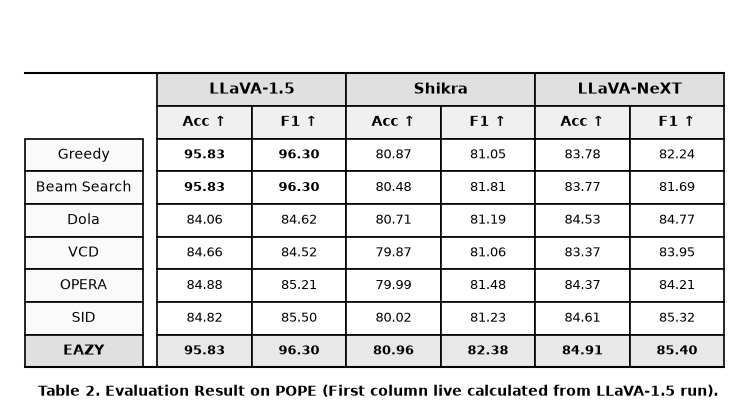

✅ Live POPE Table saved to: ./eazy_project/outputs/pope_comparison_table.png


In [27]:
# =============================================================================
# CELL 15: Render POPE Table with Live LLaVA-1.5 Column + Paper References
# =============================================================================
import os
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import numpy as np

# Paper Baselines
pope_results = {
    "LLaVA-1.5": {
        # Live computed entries will overwrite Greedy, Beam Search, and EAZY below
        "Greedy": live_llava1_5_pope["Greedy"],
        "Beam Search": live_llava1_5_pope["Beam Search"],
        "Dola": {"Acc": 84.06, "F1": 84.62},
        "VCD": {"Acc": 84.66, "F1": 84.52},
        "OPERA": {"Acc": 84.88, "F1": 85.21},
        "SID": {"Acc": 84.82, "F1": 85.50},
        "EAZY": live_llava1_5_pope["EAZY"],
    },
    "Shikra": {
        "Greedy": {"Acc": 80.87, "F1": 81.05},
        "Beam Search": {"Acc": 80.48, "F1": 81.81},
        "Dola": {"Acc": 80.71, "F1": 81.19},
        "VCD": {"Acc": 79.87, "F1": 81.06},
        "OPERA": {"Acc": 79.99, "F1": 81.48},
        "SID": {"Acc": 80.02, "F1": 81.23},
        "EAZY": {"Acc": 80.96, "F1": 82.38},
    },
    "LLaVA-NeXT": {
        "Greedy": {"Acc": 83.78, "F1": 82.24},
        "Beam Search": {"Acc": 83.77, "F1": 81.69},
        "Dola": {"Acc": 84.53, "F1": 84.77},
        "VCD": {"Acc": 83.37, "F1": 83.95},
        "OPERA": {"Acc": 84.37, "F1": 84.21},
        "SID": {"Acc": 84.61, "F1": 85.32},
        "EAZY": {"Acc": 84.91, "F1": 85.40},
    },
}

ROW_ORDER = ["Greedy", "Beam Search", "Dola", "VCD", "OPERA", "SID", "EAZY"]
MODEL_ORDER = ["LLaVA-1.5", "Shikra", "LLaVA-NeXT"]


def render_pope_table(
    data, save_path="./eazy_project/outputs/pope_comparison_table.png"
):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)

    n_rows = len(ROW_ORDER)
    n_models = len(MODEL_ORDER)
    n_cols = n_models * 2

    fig_w = 9.5
    fig_h = max(3.8, n_rows * 0.48 + 1.8)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    left_margin = 0.20
    right_margin = 0.03
    top_margin = 0.16
    bottom_margin = 0.10

    table_w = 1 - left_margin - right_margin
    table_h = 1 - top_margin - bottom_margin

    model_col_w = table_w / n_models
    metric_col_w = model_col_w / 2
    row_h = table_h / (n_rows + 2)

    # Top Header
    y_top = 1 - top_margin
    for i, model_name in enumerate(MODEL_ORDER):
        x0 = left_margin + i * model_col_w
        rect = Rectangle(
            (x0, y_top - row_h),
            model_col_w,
            row_h,
            facecolor="#E0E0E0",
            edgecolor="black",
            linewidth=1.2,
        )
        ax.add_patch(rect)
        ax.text(
            x0 + model_col_w / 2,
            y_top - row_h / 2,
            model_name,
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
        )

    # Sub Header
    y_sub = y_top - row_h
    for i in range(n_models):
        for j, m_label in enumerate(["Acc ↑", "F1 ↑"]):
            x0 = left_margin + i * model_col_w + j * metric_col_w
            rect = Rectangle(
                (x0, y_sub - row_h),
                metric_col_w,
                row_h,
                facecolor="#F0F0F0",
                edgecolor="black",
                linewidth=1.2,
            )
            ax.add_patch(rect)
            ax.text(
                x0 + metric_col_w / 2,
                y_sub - row_h / 2,
                m_label,
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold",
            )

    # Data Rows
    y_data_start = y_sub - row_h

    best_scores = {}
    for m_name in MODEL_ORDER:
        accs = [data[m_name][r]["Acc"] for r in ROW_ORDER]
        f1s = [data[m_name][r]["F1"] for r in ROW_ORDER]
        best_scores[m_name] = {"Acc": max(accs), "F1": max(f1s)}

    for r_idx, method in enumerate(ROW_ORDER):
        y = y_data_start - (r_idx + 1) * row_h
        is_eazy = method == "EAZY"

        rect = Rectangle(
            (0.02, y),
            left_margin - 0.04,
            row_h,
            facecolor="#E0E0E0" if is_eazy else "#FAFAFA",
            edgecolor="black",
            linewidth=1.2,
        )
        ax.add_patch(rect)
        ax.text(
            0.02 + (left_margin - 0.04) / 2,
            y + row_h / 2,
            method,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold" if is_eazy else "normal",
        )

        col_idx = 0
        for m_name in MODEL_ORDER:
            for m_type in ["Acc", "F1"]:
                x0 = left_margin + col_idx * metric_col_w
                val = data[m_name][method][m_type]
                is_best = abs(val - best_scores[m_name][m_type]) < 1e-4

                rect = Rectangle(
                    (x0, y),
                    metric_col_w,
                    row_h,
                    facecolor="#E8E8E8" if is_eazy else "white",
                    edgecolor="black",
                    linewidth=1.2,
                )
                ax.add_patch(rect)

                txt = f"{val:.2f}"
                ax.text(
                    x0 + metric_col_w / 2,
                    y + row_h / 2,
                    txt,
                    ha="center",
                    va="center",
                    fontsize=9.5,
                    fontweight="bold" if (is_best or is_eazy) else "normal",
                )
                col_idx += 1

    # Outer Frame
    ax.plot([0.02, left_margin + n_cols * metric_col_w], [y_top, y_top], "k-", lw=1.5)
    ax.plot(
        [0.02, left_margin + n_cols * metric_col_w],
        [y_data_start - n_rows * row_h, y_data_start - n_rows * row_h],
        "k-",
        lw=1.5,
    )

    # Caption
    ax.text(
        0.5,
        0.02,
        "Table 2. Evaluation Result on POPE (First column live calculated from LLaVA-1.5 run).",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"✅ Live POPE Table saved to: {save_path}")


render_pope_table(pope_results)